# EfficientNet-B4 — Two-Phase + WRS + FocalLoss(alpha=None)

**EEEM068 Applied Machine Learning — Group Coursework**

**Changes from exp3 baseline:**
- Two-phase training: Phase 1 freezes backbone (head only), Phase 2 unfreezes all layers
- WeightedRandomSampler to oversample minority classes
- FocalLoss with alpha=None (uniform class weights, gamma=2)


## 1. Imports

In [30]:
import os
import random
from pathlib import Path

import timm
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import transforms
from sklearn.metrics import (
    classification_report, cohen_kappa_score, confusion_matrix,
    f1_score, accuracy_score, precision_score, recall_score,
)
from sklearn.utils.class_weight import compute_class_weight

print(f'PyTorch : {torch.__version__}')
print(f'timm    : {timm.__version__}')
print(f'CUDA    : {torch.cuda.is_available()}')

PyTorch : 2.11.0+cu130
timm    : 1.0.27
CUDA    : True


## 2. Configuration

In [31]:
# ── Paths ─────────────────────────────────────────────────────
NOTEBOOK_DIR    = Path().resolve()
ROOT            = NOTEBOOK_DIR.parent

DATA_ROOT       = ROOT / 'data' / 'diabetic-retinopathy-detection'
TRAIN_DIR       = DATA_ROOT / 'train_proc'
VAL_DIR         = DATA_ROOT / 'val_proc'
TEST_LABELS_DIR = DATA_ROOT / 'test_labels_proc'
TRAIN_CSV       = DATA_ROOT / 'train_split.csv'
VAL_CSV         = DATA_ROOT / 'val_split.csv'
TEST_CSV        = DATA_ROOT / 'test_split.csv'

OUT_DIR     = ROOT / 'outputs' / 'efficientnet_b4_2phase_wrs_focal'
CKPT_DIR    = OUT_DIR / 'checkpoints'
FIGURES_DIR = OUT_DIR / 'figures'
for d in (OUT_DIR, CKPT_DIR, FIGURES_DIR):
    d.mkdir(parents=True, exist_ok=True)

# ── Experiment ────────────────────────────────────────────────
EXPERIMENT_NAME = 'efficientnet_b4_2phase_wrs_focal'
MODEL_NAME      = 'efficientnet_b4'

# ── Reproducibility ───────────────────────────────────────────
SEED = 42

# ── Data ──────────────────────────────────────────────────────
NUM_CLASSES = 5
CLASS_NAMES = ['No DR', 'Mild', 'Moderate', 'Severe', 'Proliferative']

# ── Image ─────────────────────────────────────────────────────
IMAGE_SIZE  = 224
IMGNET_MEAN = (0.485, 0.456, 0.406)
IMGNET_STD  = (0.229, 0.224, 0.225)

# ── Training (two-phase) ──────────────────────────────────────
BATCH_SIZE              = 16
PHASE1_EPOCHS           = 10       # head-only warmup
PHASE2_EPOCHS           = 25       # full fine-tune
PHASE1_HEAD_LR          = 3e-4     # head LR in phase 1
PHASE2_HEAD_LR          = 1e-4     # head LR in phase 2
PHASE2_BACK_LR          = 1e-5     # backbone LR in phase 2
WEIGHT_DECAY            = 1e-2
NUM_WORKERS             = 4
EARLY_STOPPING_PATIENCE = 8
DROPOUT                 = 0.3

# ── TTA config ────────────────────────────────────────────────
TTA_VIEWS = 5


In [32]:
# ── Seed + device ─────────────────────────────────────────────
def set_seed(seed: int = SEED) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed()
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)
if device.type == 'cuda':
    print(f'GPU   : {torch.cuda.get_device_name(0)}')
    print(f'VRAM  : {torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB')

Device: cuda
GPU   : NVIDIA RTX A4000
VRAM  : 16.7 GB


## 3. Load Pre-Split Data

In [33]:
train_df = pd.read_csv(TRAIN_CSV)
val_df   = pd.read_csv(VAL_CSV)
test_df  = pd.read_csv(TEST_CSV)

print(f'Train : {len(train_df):,} images  (dir: train_proc/)')
print(f'Val   : {len(val_df):,} images   (dir: val_proc/)')
print(f'Test  : {len(test_df):,} images   (dir: test_labels_proc/)')
print()
print(f'{"Grade":<6} {"Name":<18} {"Train":>7} {"Val":>7} {"Test":>7}')
print('-' * 52)
for g, name in enumerate(CLASS_NAMES):
    t = (train_df['level'] == g).sum()
    v = (val_df['level']   == g).sum()
    s = (test_df['level']  == g).sum()
    print(f'  {g}    {name:<18} {t:>6,}  {v:>6,}  {s:>6,}')
print()
max_c = train_df['level'].value_counts().max()
min_c = train_df['level'].value_counts().min()
print(f'Imbalance ratio (train): {max_c/min_c:.1f}\u00d7')

Train : 24,588 images  (dir: train_proc/)
Val   : 5,269 images   (dir: val_proc/)
Test  : 5,269 images   (dir: test_labels_proc/)

Grade  Name                 Train     Val    Test
----------------------------------------------------
  0    No DR              18,067   3,871   3,872
  1    Mild                1,710     367     366
  2    Moderate            3,704     794     794
  3    Severe                611     131     131
  4    Proliferative         496     106     106

Imbalance ratio (train): 36.4×


## 4. Dataset, WeightedRandomSampler, and DataLoaders


In [34]:
class DRDataset(Dataset):
    """Fundus image dataset."""

    def __init__(self, df: pd.DataFrame, data_dir: Path, transform=None):
        self.df        = df.reset_index(drop=True)
        self.data_dir  = Path(data_dir)
        self.transform = transform

    def __len__(self) -> int:
        return len(self.df)

    def __getitem__(self, idx: int):
        row   = self.df.iloc[idx]
        image = Image.open(self.data_dir / f"{row['image']}.jpeg").convert('RGB')
        label = int(row['level'])
        if self.transform is not None:
            image = self.transform(image)
        return image, label


# ── Augmentation ─────────────────────────────────────────────────────────────
train_transform = transforms.Compose([
    transforms.Resize(int(IMAGE_SIZE * 1.14)),
    transforms.RandomCrop(IMAGE_SIZE),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomApply([transforms.RandomRotation(degrees=30)], p=0.5),
    transforms.RandomApply([
        transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.05)
    ], p=0.4),
    transforms.RandomApply([
        transforms.RandomAffine(degrees=0, translate=(0.05, 0.05), scale=(0.95, 1.05))
    ], p=0.3),
    transforms.ToTensor(),
    transforms.Normalize(IMGNET_MEAN, IMGNET_STD),
    transforms.RandomErasing(p=0.2),
])

val_transform = transforms.Compose([
    transforms.Resize(int(IMAGE_SIZE * 1.05)),
    transforms.CenterCrop(IMAGE_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(IMGNET_MEAN, IMGNET_STD),
])

train_ds = DRDataset(train_df, TRAIN_DIR, transform=train_transform)
val_ds   = DRDataset(val_df,   VAL_DIR,   transform=val_transform)
test_ds  = DRDataset(test_df,  TEST_LABELS_DIR, transform=val_transform)

# ── WeightedRandomSampler ─────────────────────────────────────────────────────
# Compute per-sample weights so every class is sampled at equal frequency per epoch.
class_counts = train_df['level'].value_counts().sort_index()          # counts per class
class_weights = 1.0 / class_counts.values.astype(float)              # inverse frequency
sample_weights = torch.tensor(
    [class_weights[label] for label in train_df['level'].values],
    dtype=torch.double,
)
wrs = WeightedRandomSampler(
    weights     = sample_weights,
    num_samples = len(sample_weights),
    replacement = True,
)
print('Class counts      :', class_counts.to_dict())
print('Class weights (WRS):', {n: f'{w:.4f}' for n, w in zip(CLASS_NAMES, class_weights)})

# ── DataLoaders ───────────────────────────────────────────────────────────────
train_loader = DataLoader(
    train_ds, batch_size=BATCH_SIZE, sampler=wrs,    # WRS replaces shuffle
    num_workers=NUM_WORKERS, pin_memory=True,
    drop_last=True, persistent_workers=NUM_WORKERS > 0,
)
val_loader = DataLoader(
    val_ds, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=True,
    persistent_workers=NUM_WORKERS > 0,
)
test_loader = DataLoader(
    test_ds, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=True,
    persistent_workers=NUM_WORKERS > 0,
)
print(f'Train batches: {len(train_loader)} | Val batches: {len(val_loader)} | Test batches: {len(test_loader)}')
print('Sampler: WeightedRandomSampler (minority classes upsampled)')


Class counts      : {0: 18067, 1: 1710, 2: 3704, 3: 611, 4: 496}
Class weights (WRS): {'No DR': '0.0001', 'Mild': '0.0006', 'Moderate': '0.0003', 'Severe': '0.0016', 'Proliferative': '0.0020'}
Train batches: 1536 | Val batches: 330 | Test batches: 330
Sampler: WeightedRandomSampler (minority classes upsampled)


## 5. Model

`efficientnet_b4` — pre-trained on ImageNet-1k, 19.3M params, feat_dim=1792.

**B4 vs B3:** Deeper network (more MBConv blocks), wider channels (1792 vs 1536 feature dim).
At 224×224 input it runs below native resolution (380×380) but the deeper architecture
still extracts richer features than B3 at the same input size.

In [35]:
def build_efficientnet_model(pretrained: bool = True) -> nn.Module:
    """Build EfficientNet-B4 with a custom 5-class classification head."""
    backbone = timm.create_model(
        MODEL_NAME,
        pretrained  = pretrained,
        num_classes = 0,
        global_pool = 'avg',
    )
    feat_dim = backbone.num_features   # 1792 for B4

    backbone.custom_head = nn.Sequential(
        nn.LayerNorm(feat_dim),
        nn.Dropout(p=DROPOUT),
        nn.Linear(feat_dim, NUM_CLASSES),
    )

    _base_forward = backbone.forward
    backbone.forward = lambda x: backbone.custom_head(_base_forward(x))

    total = sum(p.numel() for p in backbone.parameters()) / 1e6
    print(f'EfficientNet-B4 | {total:.1f}M params | feat_dim={feat_dim}')
    return backbone


model = build_efficientnet_model(pretrained=True).to(device)

EfficientNet-B4 | 17.6M params | feat_dim=1792


## 6. FocalLoss + Optimiser + Two-Phase Schedulers

**FocalLoss(alpha=None, gamma=2)** — down-weights easy examples, focuses on hard ones.
alpha=None means uniform class priors (no extra class weighting; WRS already handles balance).
Two-phase training: Phase 1 trains head only (backbone frozen), Phase 2 unfreezes all.


In [36]:
# ── Focal Loss ───────────────────────────────────────────────────────────────
class FocalLoss(nn.Module):
    """Focal Loss for multi-class classification.
    alpha=None → uniform class priors (WRS already balances sampling).
    gamma=2 is the standard down-weighting exponent for easy examples.
    """
    def __init__(self, alpha=None, gamma: float = 2.0, reduction: str = 'mean'):
        super().__init__()
        self.alpha     = alpha      # None or 1-D tensor of per-class weights
        self.gamma     = gamma
        self.reduction = reduction

    def forward(self, logits: torch.Tensor, targets: torch.Tensor) -> torch.Tensor:
        ce   = F.cross_entropy(logits, targets, weight=self.alpha, reduction='none')
        pt   = torch.exp(-ce)
        loss = (1 - pt) ** self.gamma * ce
        return loss.mean() if self.reduction == 'mean' else loss.sum()


criterion = FocalLoss(alpha=None, gamma=2.0)
print('Loss:', criterion)


# ── Phase 1 setup: freeze backbone, train head only ───────────────────────────
def freeze_backbone(model: nn.Module) -> None:
    """Freeze all parameters except the custom_head."""
    for name, param in model.named_parameters():
        param.requires_grad = ('custom_head' in name)

def unfreeze_all(model: nn.Module) -> None:
    """Unfreeze all parameters."""
    for param in model.parameters():
        param.requires_grad = True


freeze_backbone(model)
trainable_p1 = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Phase 1 — trainable params: {trainable_p1:,} (head only, backbone frozen)')

optimizer_p1 = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=PHASE1_HEAD_LR, weight_decay=WEIGHT_DECAY,
)
scheduler_p1 = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer_p1, T_max=PHASE1_EPOCHS
)


Loss: FocalLoss()
Phase 1 — trainable params: 12,549 (head only, backbone frozen)


## 7. Training Loop

In [37]:
use_amp = device.type == 'cuda'
scaler  = torch.amp.GradScaler('cuda', enabled=use_amp)


def run_epoch(loader, optimizer=None, train_mode: bool = True, grad_clip: float = 1.0):
    """Single train or eval pass. Returns (loss, labels, preds, kappa)."""
    model.train(train_mode)
    total_loss, total = 0.0, 0
    all_preds, all_labels = [], []

    for images, labels in tqdm(loader, leave=False,
                               desc='train' if train_mode else 'val  '):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        with torch.autocast(device_type='cuda', enabled=use_amp):
            logits = model(images)
            loss   = criterion(logits, labels)

        if train_mode:
            optimizer.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            if grad_clip > 0:
                scaler.unscale_(optimizer)
                nn.utils.clip_grad_norm_(model.parameters(), grad_clip)
            scaler.step(optimizer)
            scaler.update()

        total_loss += loss.item() * labels.size(0)
        total      += labels.size(0)
        all_preds.extend(logits.argmax(dim=1).cpu().tolist())
        all_labels.extend(labels.cpu().tolist())

    avg_loss = total_loss / total
    kappa    = cohen_kappa_score(all_labels, all_preds, weights='quadratic')
    return avg_loss, all_labels, all_preds, kappa


In [38]:
best_path      = CKPT_DIR / f'{EXPERIMENT_NAME}_best.pt'
best_val_kappa = -1.0
history = {'train_loss': [], 'val_loss': [], 'train_kappa': [], 'val_kappa': [], 'phase': []}

print('=' * 60)
print('  PHASE 1 — Head only (backbone frozen)')
print('=' * 60)
print(f"{'Epoch':<8} {'Tr Loss':>10} {'Tr κ':>8} {'Val Loss':>10} {'Val κ':>8}")
print('─' * 52)

patience_left = EARLY_STOPPING_PATIENCE

for epoch in range(1, PHASE1_EPOCHS + 1):
    tr_loss, tr_labels, tr_preds, tr_kappa = run_epoch(train_loader, optimizer_p1, train_mode=True)
    vl_loss, vl_labels, vl_preds, vl_kappa = run_epoch(val_loader,   optimizer_p1, train_mode=False)
    scheduler_p1.step()

    history['train_loss'].append(tr_loss);   history['val_loss'].append(vl_loss)
    history['train_kappa'].append(tr_kappa); history['val_kappa'].append(vl_kappa)
    history['phase'].append(1)

    marker = ''
    if vl_kappa > best_val_kappa:
        best_val_kappa = vl_kappa
        patience_left  = EARLY_STOPPING_PATIENCE
        torch.save({'epoch': epoch, 'model_state': model.state_dict(),
                    'val_kappa': vl_kappa, 'val_loss': vl_loss}, best_path)
        marker = '  ★'
    else:
        patience_left -= 1
        if patience_left <= 0:
            print(f'Early stopping (phase 1) at epoch {epoch}.')
            break

    print(f'{epoch:<8} {tr_loss:>10.4f} {tr_kappa:>8.4f} {vl_loss:>10.4f} {vl_kappa:>8.4f}{marker}')

print(f'\nPhase 1 best val κ = {best_val_kappa:.4f}')

# ── Phase 2: unfreeze all, lower LR ──────────────────────────────────────────
unfreeze_all(model)
trainable_p2 = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'\n{"=" * 60}')
print('  PHASE 2 — All layers unfrozen')
print(f'{"=" * 60}')
print(f'Trainable params: {trainable_p2:,}')

backbone_params = [p for n, p in model.named_parameters() if 'custom_head' not in n]
head_params     = [p for n, p in model.named_parameters() if 'custom_head'     in n]

optimizer_p2 = torch.optim.AdamW(
    [{'params': backbone_params, 'lr': PHASE2_BACK_LR},
     {'params': head_params,     'lr': PHASE2_HEAD_LR}],
    weight_decay=WEIGHT_DECAY,
)
scheduler_p2 = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer_p2, T_max=PHASE2_EPOCHS
)

patience_left = EARLY_STOPPING_PATIENCE

print(f"{'Epoch':<8} {'Tr Loss':>10} {'Tr κ':>8} {'Val Loss':>10} {'Val κ':>8}")
print('─' * 52)

for epoch in range(1, PHASE2_EPOCHS + 1):
    tr_loss, tr_labels, tr_preds, tr_kappa = run_epoch(train_loader, optimizer_p2, train_mode=True)
    vl_loss, vl_labels, vl_preds, vl_kappa = run_epoch(val_loader,   optimizer_p2, train_mode=False)
    scheduler_p2.step()

    history['train_loss'].append(tr_loss);   history['val_loss'].append(vl_loss)
    history['train_kappa'].append(tr_kappa); history['val_kappa'].append(vl_kappa)
    history['phase'].append(2)

    global_ep = len(history['train_loss'])
    marker = ''
    if vl_kappa > best_val_kappa:
        best_val_kappa = vl_kappa
        patience_left  = EARLY_STOPPING_PATIENCE
        torch.save({'epoch': global_ep, 'model_state': model.state_dict(),
                    'val_kappa': vl_kappa, 'val_loss': vl_loss}, best_path)
        marker = '  ★'
    else:
        patience_left -= 1
        if patience_left <= 0:
            print(f'Early stopping (phase 2) at epoch {epoch}.')
            break

    print(f'P2-{epoch:<5} {tr_loss:>10.4f} {tr_kappa:>8.4f} {vl_loss:>10.4f} {vl_kappa:>8.4f}{marker}')

print(f'\nBest val κ = {best_val_kappa:.4f}  →  {best_path.name}')


  PHASE 1 — Head only (backbone frozen)
Epoch       Tr Loss     Tr κ   Val Loss    Val κ
────────────────────────────────────────────────────


train:   0%|          | 0/1536 [00:00<?, ?it/s]

val  :   0%|          | 0/330 [00:00<?, ?it/s]

1            0.9015   0.4813     0.9481   0.2281  ★


train:   0%|          | 0/1536 [00:00<?, ?it/s]

...

val  :   0%|          | 0/330 [00:00<?, ?it/s]

P2-22        0.5385   0.7294     0.5349   0.4690


train:   0%|          | 0/1536 [00:00<?, ?it/s]

val  :   0%|          | 0/330 [00:00<?, ?it/s]

Early stopping (phase 2) at epoch 23.

Best val κ = 0.4959  →  efficientnet_b4_2phase_wrs_focal_best.pt


## 8. Loss + Kappa Curves

Epoch       Tr Loss     Tr κ   Val Loss    Val κ
────────────────────────────────────────────────────
1            0.9015   0.4813     0.9481   0.2281
2            0.8286   0.5368     0.7008   0.2894
3            0.8153   0.5432     0.6969   0.3186
4            0.8038   0.5420     0.6888   0.3129
5            0.7904   0.5609     0.6296   0.3365
6            0.7836   0.5530     0.6547   0.3342
7            0.7692   0.5663     0.6514   0.3273
8            0.7624   0.5650     0.6480   0.3377
9            0.7557   0.5743     0.6633   0.3220
10           0.7569   0.5790     0.6449   0.3333
11           0.7421   0.5914     0.5896   0.3873
12           0.7209   0.6026     0.6778   0.3511
13           0.6948   0.6384     0.6412   0.3644
14           0.6788   0.6434     0.5830   0.4081
15           0.6631   0.6643     0.5714   0.4298
16           0.6438   0.6733     0.6060   0.4028
17           0.6334   0.6802     0.5641   0.4277
18           0.6254   0.6797     0.5031   0.4745
19           0.6

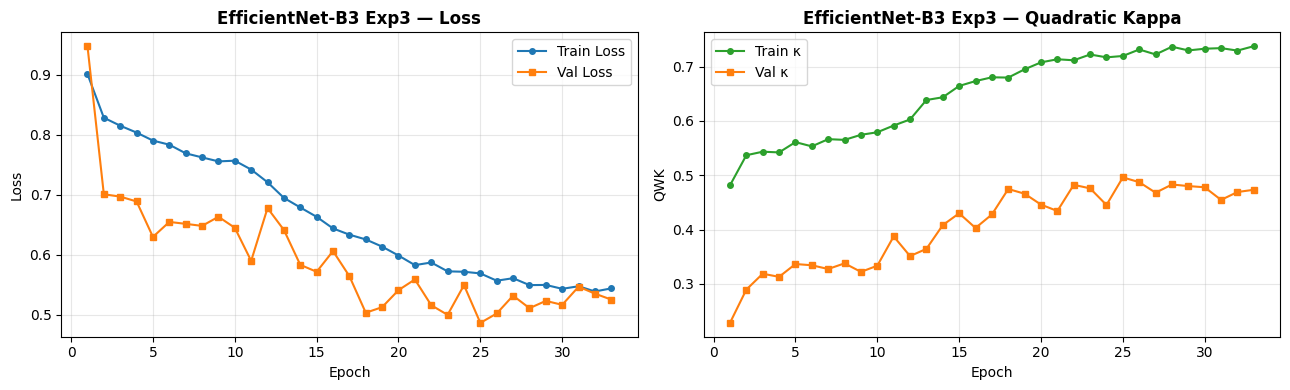

In [39]:
epochs_ran = range(1, len(history['train_loss']) + 1)

print(f"{'Epoch':<8} {'Tr Loss':>10} {'Tr \u03ba':>8} {'Val Loss':>10} {'Val \u03ba':>8}")
print('\u2500' * 52)
for ep, (tl, tk, vl, vk) in enumerate(
    zip(history['train_loss'], history['train_kappa'],
        history['val_loss'],   history['val_kappa']), 1
):
    print(f'{ep:<8} {tl:>10.4f} {tk:>8.4f} {vl:>10.4f} {vk:>8.4f}')

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(epochs_ran, history['train_loss'], label='Train Loss', marker='o', markersize=4)
axes[0].plot(epochs_ran, history['val_loss'],   label='Val Loss',   marker='s', markersize=4)
axes[0].set_title('EfficientNet-B3 Exp3 \u2014 Loss', fontweight='bold')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss')
axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(epochs_ran, history['train_kappa'], label='Train \u03ba', marker='o', markersize=4, color='tab:green')
axes[1].plot(epochs_ran, history['val_kappa'],   label='Val \u03ba',   marker='s', markersize=4, color='tab:orange')
axes[1].set_title('EfficientNet-B3 Exp3 \u2014 Quadratic Kappa', fontweight='bold')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('QWK')
axes[1].legend(); axes[1].grid(alpha=0.3)

plt.tight_layout()
fig.savefig(FIGURES_DIR / f'{EXPERIMENT_NAME}_curves.png', dpi=150, bbox_inches='tight')
plt.show()

## 9. Evaluation on Test Set

In [40]:
# ── Load best checkpoint ──────────────────────────────────────────────────────
model = build_efficientnet_model(pretrained=False).to(device)
criterion = FocalLoss(alpha=None, gamma=2.0)

ckpt = torch.load(best_path, map_location=device, weights_only=False)
model.load_state_dict(ckpt['model_state'])
print(f'Loaded: {best_path.name}')
print(f'epoch={ckpt["epoch"]}  val_kappa={ckpt["val_kappa"]:.4f}')

# ── Standard eval ─────────────────────────────────────────────────────────────
_, y_true, y_pred, qwk = run_epoch(test_loader, train_mode=False)
print(f'\nTest QWK: {qwk:.4f}')
print('\nClassification Report (Test Set):')
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=3))
print(f'Quadratic Weighted Kappa: {qwk:.4f}')


EfficientNet-B4 | 17.6M params | feat_dim=1792
Loaded: efficientnet_b4_2phase_wrs_focal_best.pt
epoch=25  val_kappa=0.4959


val  :   0%|          | 0/330 [00:00<?, ?it/s]


Test QWK: 0.5200

Classification Report (Test Set):
               precision    recall  f1-score   support

        No DR      0.854     0.709     0.775      3872
         Mild      0.121     0.298     0.172       366
     Moderate      0.372     0.343     0.357       794
       Severe      0.246     0.351     0.289       131
Proliferative      0.283     0.623     0.389       106

     accuracy                          0.615      5269
    macro avg      0.375     0.465     0.396      5269
 weighted avg      0.704     0.615     0.650      5269

Quadratic Weighted Kappa: 0.5200


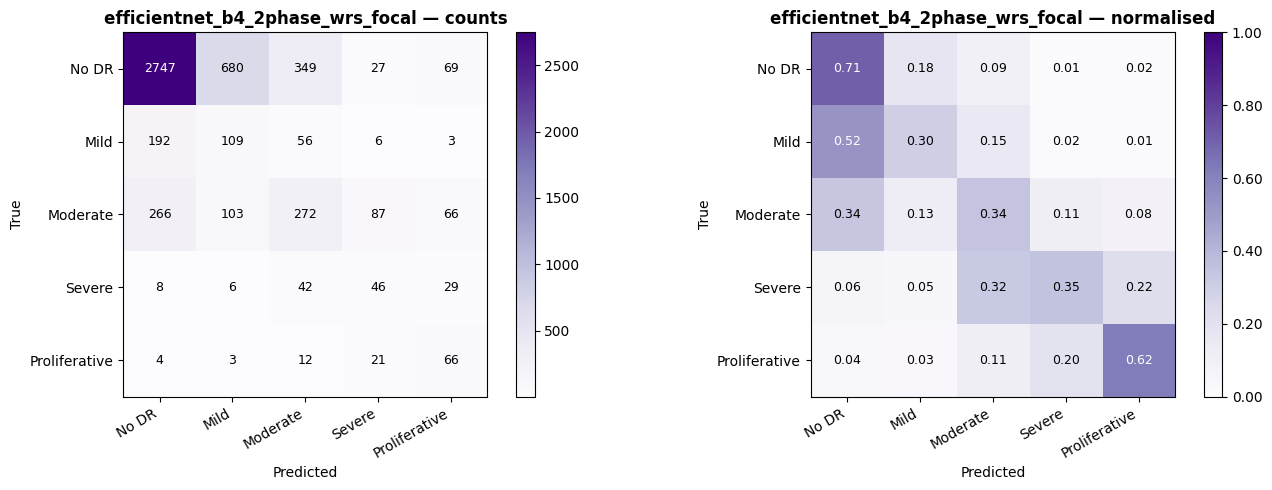

In [41]:
cm = confusion_matrix(y_true, y_pred)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, data, title, fmt, cmap in zip(
    axes,
    [cm, cm.astype(float) / cm.sum(axis=1, keepdims=True)],
    [f'{EXPERIMENT_NAME} \u2014 counts', f'{EXPERIMENT_NAME} \u2014 normalised'],
    ['d', '.2f'],
    ['Purples', 'Purples'],
):
    im = ax.imshow(data, interpolation='nearest', cmap=cmap,
                   vmin=None if fmt=='d' else 0, vmax=None if fmt=='d' else 1)
    fig.colorbar(im, ax=ax, format=(None if fmt=='d' else '%.2f'))
    ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(CLASS_NAMES, rotation=30, ha='right')
    ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(CLASS_NAMES)
    ax.set_xlabel('Predicted'); ax.set_ylabel('True'); ax.set_title(title, fontweight='bold')
    thresh = (data.max() / 2) if fmt=='d' else 0.5
    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            ax.text(j, i, format(data[i,j], fmt), ha='center', va='center', fontsize=9,
                    color='white' if data[i,j] > thresh else 'black')

plt.tight_layout()
fig.savefig(FIGURES_DIR / f'{EXPERIMENT_NAME}_confusion.png', dpi=150, bbox_inches='tight')
plt.show()

## 10. Results Summary

In [42]:
qwk    = cohen_kappa_score(y_true, y_pred, weights='quadratic')
acc    = accuracy_score(y_true, y_pred)
f1_per = f1_score(y_true, y_pred, average=None, labels=list(range(5)))

print('=' * 60)
print('  EfficientNet-B4 Exp3 (224px + TTA) \u2014 TEST SET RESULTS')
print('=' * 60)
print(f'  Test QWK      : {qwk:.4f}')
print(f'  Test Accuracy : {acc:.4f}  (not the primary metric)')
print(f'  Macro F1      : {f1_score(y_true, y_pred, average="macro"):.4f}')
print(f'  Macro Prec.   : {precision_score(y_true, y_pred, average="macro", zero_division=0):.4f}')
print(f'  Macro Recall  : {recall_score(y_true, y_pred, average="macro", zero_division=0):.4f}')
print()
print('  Per-class F1:')
for name, f1 in zip(CLASS_NAMES, f1_per):
    bar = '\u2588' * int(f1 * 20)
    print(f'    {name:<18}: {f1:.4f}  {bar}')
print('=' * 60)

# ── Save results ─────────────────────────────────────────────────────────────
import json as _json
results = {
    'model': 'efficientnet_b4_exp3',
    'qwk': qwk,
    'accuracy': acc,
    'macro_f1': f1_score(y_true, y_pred, average='macro'),
    'f1_per_class': {name: float(f) for name, f in zip(CLASS_NAMES, f1_per)},
    'history': history,
}
with open(OUT_DIR / f'{EXPERIMENT_NAME}_results.json', 'w') as f:
    _json.dump(results, f, indent=2)
print(f'\nResults saved to {OUT_DIR / f"{EXPERIMENT_NAME}_results.json"}')

  EfficientNet-B4 Exp3 (224px + TTA) — TEST SET RESULTS
  Test QWK      : 0.5200
  Test Accuracy : 0.6149  (not the primary metric)
  Macro F1      : 0.3965
  Macro Prec.   : 0.3752
  Macro Recall  : 0.4647

  Per-class F1:
    No DR             : 0.7750  ███████████████
    Mild              : 0.1721  ███
    Moderate          : 0.3567  ███████
    Severe            : 0.2893  █████
    Proliferative     : 0.3894  ███████

Results saved to /scratch/AML_G14_CW/outputs/efficientnet_b4_2phase_wrs_focal/efficientnet_b4_2phase_wrs_focal_results.json


## 11. Cross-Model Comparison

In [43]:
import json as _json

print('=' * 90)
print('  FULL MODEL COMPARISON')
print('=' * 90)
print(f'  {"Model":<30} {"Params":>8} {"Input":>8} {"Test QWK":>10} {"Macro F1":>10}')
print('-' * 90)

# Current model
macro_f1 = f1_score(y_true, y_pred, average='macro')
print(f'  {"B4 (224+TTA, this)":<30} {"~10.7M":>8} {"300":>8} {qwk:>10.4f} {macro_f1:>10.4f}')

# Try loading B0 baseline
try:
    with open(ROOT / 'outputs' / 'efficientnet_b0' / 'efficientnet_b0_results.json') as f:
        b0 = _json.load(f)
    print(f'  {"EfficientNet-B0 (Baseline)":<30} {"~4M":>8} {"224":>8} {b0["qwk"]:>10.4f} {b0["macro_f1"]:>10.4f}')
    delta = qwk - b0['qwk']
    print(f'\n  B3 vs B0 delta: {delta:+.4f} QWK')
except FileNotFoundError:
    print(f'  EfficientNet-B0 results not found')

try:
    with open(ROOT / 'outputs' / 'efficientnet_b3_exp3' / 'efficientnet_b3_exp3_results.json') as f:
        v3 = _json.load(f)
    print(f'  {"B3 v3 (300px, no TTA)":<35} {"":>8} {v3["qwk"]:>10.4f} {v3["macro_f1"]:>10.4f}')
except FileNotFoundError:
    pass

# Try loading SwinV2
try:
    with open(ROOT / 'outputs' / 'swinv2_small_baseline' / 'baseline_results.json') as f:
        swin = _json.load(f)
    print(f'  {"SwinV2-Small (Baseline)":<30} {"~49M":>8} {"256":>8} {swin["qwk"]:>10.4f} {swin["macro_f1"]:>10.4f}')
except FileNotFoundError:
    pass

print('=' * 90)

  FULL MODEL COMPARISON
  Model                            Params    Input   Test QWK   Macro F1
------------------------------------------------------------------------------------------
  B4 (224+TTA, this)               ~10.7M      300     0.5200     0.3965
  EfficientNet-B0 (Baseline)          ~4M      224     0.5735     0.4301

  B3 vs B0 delta: -0.0535 QWK
  B3 v3 (300px, no TTA)                            0.5166     0.4344
